# Self-Attention, Multi-Head Attention, and Cross-Attention

---

Creator: Chung-En Johnny Yu

Content updated: 2026-10-29

Live companion for **M15 — Tokenization + Attention** (attention half). The course notebook `02_attention.ipynb` walks through Raschka's Chapter 3 in full. This companion is the condensed, interview-oriented version: the same core figures and code, plus measurements and tests that answer the usual follow-up questions, efficient implementations, and cross-attention.

**Sources** — every section is tagged:

| Tag | Source | License |
|---|---|---|
| 📗 **[Ch3]** | Sebastian Raschka, *Build a Large Language Model (From Scratch)* (Manning, 2024), Ch. 3 — [notebook](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch03/01_main-chapter-code/ch03.ipynb) | Apache-2.0 (code/text); figures excluded from that license, copied into `02-self_and_cross_attention/img/` with attribution (see `SOURCE.md`) |
| 📗 **[MHA bonus]** | Raschka, [`ch03/02_bonus_efficient-multihead-attention`](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch03/02_bonus_efficient-multihead-attention) | Apache-2.0 |
| 📗 **[Buffers bonus]** | Raschka, [`ch03/03_understanding-buffers`](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch03/03_understanding-buffers) | Apache-2.0 |
| 🧪 **[Added]** | Written for this companion | — |

CPU only, a few seconds.

| Part | Question it answers |
|---|---|
| 1 | What are Q, K, V — step by step and in shapes? |
| 2 | Why divide by $\sqrt{d_k}$? (measured, not just stated) |
| 3 | Where does the causal mask go, and how do we *test* it? |
| 4 | Multi-head attention: what is split, what is concatenated? |
| 5 | Efficient implementations: fused QKV and `scaled_dot_product_attention` |
| 6 | Cross-attention: Q from one sequence, K/V from another |
| 7 | Cost: what exactly is $O(T^2)$? |
| 8 | Interview-style check questions |

---

In [1]:
import math, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

print("torch", torch.__version__)

torch 2.13.0


## 1. Self-attention with trainable weights, step by step

📗 *[Ch3] §3.4 text, code and figures; 🧪 [Added] intuition*

🧪 **Intuition — a soft dictionary lookup.** A *query* is what the current token is looking for, a *key* is what each token advertises about itself, and a *value* is the content it hands over. A Python dict returns the value whose key matches exactly; attention returns a **weighted average of all values**, weighted by how well each key matches the query — and because everything is differentiable, the projections are learned.

📗 This self-attention mechanism is used in the original transformer, the GPT models and most other popular LLMs; it is also called **scaled dot-product attention**. Three trainable weight matrices $W_q$, $W_k$, $W_v$ project the embedded input tokens $x^{(i)}$ into query, key and value vectors:
$q^{(i)} = x^{(i)}W_q$, $\;k^{(i)} = x^{(i)}W_k$, $\;v^{(i)} = x^{(i)}W_v$.

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/02-self_and_cross_attention/img/ch03_14.webp?raw=true" width="600px">

*Figure: step 1 — project each input into a query, key and value; the second token "journey" serves as the current query. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/14.webp`).*

The running example is the six-token sentence "Your journey starts with one step", each token embedded in 3 dimensions. As in the book, we project to `d_out = 2` so the numbers are easy to follow (GPT models normally keep input and output size equal).

In [2]:
# Source: Raschka, LLMs-from-scratch ch03.ipynb (Apache-2.0)
inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55]] # step     (x^6)
)

x_2 = inputs[1] # second input element
d_in = inputs.shape[1] # the input embedding size, d=3
d_out = 2 # the output embedding size, d=2

torch.manual_seed(123)

W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key   = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)

query_2 = x_2 @ W_query # _2 because it's with respect to the 2nd input element
keys = inputs @ W_key
values = inputs @ W_value

print("query_2:", query_2)
print("keys.shape:", keys.shape)
print("values.shape:", values.shape)

query_2: tensor([0.4306, 1.4551])
keys.shape: torch.Size([6, 2])
values.shape: torch.Size([6, 2])


**Steps 2 and 3**: the unnormalized attention scores are dot products between the query and every key; the attention weights are their softmax, after scaling by $\sqrt{d_k}$:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/02-self_and_cross_attention/img/ch03_16.webp?raw=true" width="600px">

*Figure: scores $\omega_{2j}=q^{(2)}\cdot k^{(j)}$, then weights $\alpha_{2j}$ via scaled softmax. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/16.webp`).*

In [3]:
# Source: Raschka, LLMs-from-scratch ch03.ipynb (Apache-2.0)
attn_scores_2 = query_2 @ keys.T # All attention scores for given query
print(attn_scores_2)

d_k = keys.shape[1]
attn_weights_2 = torch.softmax(attn_scores_2 / d_k**0.5, dim=-1)
print(attn_weights_2)

tensor([1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440])
tensor([0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820])


**Step 4**: the context vector for token 2 is the attention-weighted sum of all value vectors:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/02-self_and_cross_attention/img/ch03_17.webp?raw=true" width="600px">

*Figure: context vector $z^{(2)}=\sum_j \alpha_{2j}v^{(j)}$. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/17.webp`).*

In [4]:
# Source: Raschka, LLMs-from-scratch ch03.ipynb (Apache-2.0)
context_vec_2 = attn_weights_2 @ values
print(context_vec_2)

tensor([0.3061, 0.8210])


🧪 **Everything at once, in matrix form.** Doing this for every token simultaneously gives

$$
\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\Big(\frac{QK^\top}{\sqrt{d_k}}\Big)V,
$$

| Tensor | Shape (single head, batch $B$) |
|---|---|
| $X$ | $(B, T, d_{in})$ |
| $Q, K$ | $(B, T, d_k)$ |
| $V$ | $(B, T, d_v)$ |
| scores $QK^\top$ | $(B, T, T)$ ← one score per (query, key) pair |
| output | $(B, T, d_v)$ |

In [5]:
# 🧪 [Added] the matrix form reproduces the step-by-step result for token 2
Q, K, V = inputs @ W_query, inputs @ W_key, inputs @ W_value
Z = torch.softmax(Q @ K.T / d_k**0.5, dim=-1) @ V
assert torch.allclose(Z[1], context_vec_2)
print("row 2 of softmax(QKᵀ/√d_k)V == step-by-step context vector ✓  shape", tuple(Z.shape))

row 2 of softmax(QKᵀ/√d_k)V == step-by-step context vector ✓  shape (6, 2)


## 2. Why divide by $\sqrt{d_k}$?

🧪 *[Added]*

If the entries of $q$ and $k$ are independent with mean 0 and variance 1, then $q\cdot k=\sum_{i=1}^{d_k} q_i k_i$ has variance $d_k$. Large scores push softmax into **saturation** — one weight ≈ 1, the rest ≈ 0 — and the gradient of softmax vanishes. Dividing by $\sqrt{d_k}$ restores unit variance regardless of head size.

d_k=   4  var(q·k)=    4.0   var(q·k/√d_k)=0.99
d_k=  64  var(q·k)=   64.1   var(q·k/√d_k)=1.00


d_k= 512  var(q·k)=  505.8   var(q·k/√d_k)=0.99


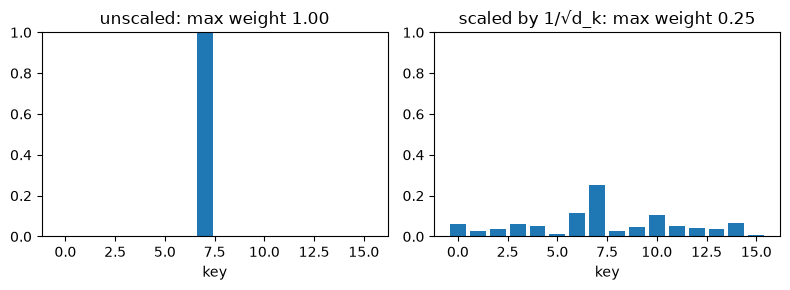

softmax Jacobian norm  unscaled: 0.0 | scaled: 0.2933


In [6]:
# 🧪 [Added]
torch.manual_seed(0)
for d_k_ in [4, 64, 512]:
    qs, ks = torch.randn(10_000, d_k_), torch.randn(10_000, d_k_)
    dots = (qs * ks).sum(-1)
    print(f"d_k={d_k_:4d}  var(q·k)={dots.var():7.1f}   var(q·k/√d_k)={(dots / math.sqrt(d_k_)).var():.2f}")

d_k_, T = 512, 16
qv, kv = torch.randn(T, d_k_), torch.randn(T, d_k_)
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, (title, s) in zip(axes, [("unscaled", qv @ kv.T), ("scaled by 1/√d_k", qv @ kv.T / math.sqrt(d_k_))]):
    p = F.softmax(s, -1)
    ax.bar(range(T), p[0]); ax.set_title(f"{title}: max weight {p[0].max():.2f}")
    ax.set_xlabel("key"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

def softmax_grad_norm(s):
    p = F.softmax(s, -1)
    return (torch.diag(p) - p[:, None] * p[None, :]).norm().item()   # norm of the softmax Jacobian
print("softmax Jacobian norm  unscaled:", round(softmax_grad_norm(qv[0] @ kv.T), 4),
      "| scaled:", round(softmax_grad_norm(qv[0] @ kv.T / math.sqrt(d_k_)), 4))

Unscaled, the distribution is (nearly) one-hot and the Jacobian is close to zero — learning stalls. Scaled, the weights stay soft and gradients flow.

## 3. Hiding future words with causal attention

📗 *[Ch3] §3.5 text, code and figures; 🧪 [Added] leakage test*

- In causal attention, the attention weights above the diagonal are masked, ensuring that for any given input, the LLM is unable to utilize future tokens while calculating the context vectors
- Each next-word prediction should only depend on the preceding words

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/02-self_and_cross_attention/img/ch03_19.webp?raw=true" width="500px">

*Figure: attention weights before and after masking the future tokens. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/19.webp`).*

- Instead of zeroing out attention weights above the diagonal and renormalizing, we can mask the unnormalized attention scores above the diagonal with **negative infinity before** they enter the softmax function:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/02-self_and_cross_attention/img/ch03_21.webp?raw=true" width="450px">

*Figure: mask with $-\infty$, then softmax. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/21.webp`).*

In [7]:
# Source: Raschka, LLMs-from-scratch ch03.ipynb (Apache-2.0)
attn_scores = Q @ K.T
context_length = attn_scores.shape[0]

mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
masked = attn_scores.masked_fill(mask.bool(), -torch.inf)
print(masked)

attn_weights = torch.softmax(masked / K.shape[-1]**0.5, dim=-1)
print(attn_weights)

tensor([[0.9231,   -inf,   -inf,   -inf,   -inf,   -inf],
        [1.2705, 1.8524,   -inf,   -inf,   -inf,   -inf],
        [1.2544, 1.8284, 1.7877,   -inf,   -inf,   -inf],
        [0.6973, 1.0167, 0.9941, 0.5925,   -inf,   -inf],
        [0.6114, 0.8819, 0.8626, 0.5121, 0.2707,   -inf],
        [0.8995, 1.3165, 1.2871, 0.7682, 0.3937, 1.0996]])
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3986, 0.6014, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2526, 0.3791, 0.3683, 0.0000, 0.0000, 0.0000],
        [0.2265, 0.2839, 0.2794, 0.2103, 0.0000, 0.0000],
        [0.1952, 0.2363, 0.2331, 0.1820, 0.1534, 0.0000],
        [0.1557, 0.2092, 0.2048, 0.1419, 0.1089, 0.1794]])


Each row still sums to 1, and every entry above the diagonal is exactly 0. (Masking *after* softmax would leave rows that no longer sum to 1.)

🧪 **How to test a causal mask:** change a future token and check that the outputs for earlier positions do not move at all. Then confirm we match PyTorch's fused kernel.

In [8]:
# 🧪 [Added]
def attention(q, k, v, mask=None):
    """q: (..., T_q, d_k), k: (..., T_k, d_k), v: (..., T_k, d_v); mask: True = blocked."""
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    if mask is not None:
        scores = scores.masked_fill(mask, float("-inf"))           # BEFORE softmax
    weights = F.softmax(scores, dim=-1)
    return weights @ v, weights

torch.manual_seed(0)
B, T, d = 2, 6, 16
X = torch.randn(B, T, d)
Wq, Wk, Wv = (nn.Linear(d, d, bias=False) for _ in range(3))
causal = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)

out1, w = attention(Wq(X), Wk(X), Wv(X), causal)
X2 = X.clone(); X2[:, 4] += 100.0                                   # perturb token 4 only
out2, _ = attention(Wq(X2), Wk(X2), Wv(X2), causal)

assert torch.allclose(out1[:, :4], out2[:, :4]), "future leakage!"
assert not torch.allclose(out1[:, 4:], out2[:, 4:])
assert torch.allclose(w.sum(-1), torch.ones(B, T))
print("positions 0-3 unchanged after editing token 4: no future leakage ✓")

ref = F.scaled_dot_product_attention(Wq(X), Wk(X), Wv(X), is_causal=True)
assert torch.allclose(out1, ref, atol=1e-5)
print("matches F.scaled_dot_product_attention(is_causal=True) ✓")

positions 0-3 unchanged after editing token 4: no future leakage ✓
matches F.scaled_dot_product_attention(is_causal=True) ✓


📗 *[Buffers bonus]* **Why the book stores the mask with `register_buffer`.** Buffers are tensor attributes of a module that, unlike parameters, are not updated during training. Registering the mask as a buffer means it moves with the model when you call `.to("cuda")` (a plain tensor attribute would stay on the CPU and cause a device-mismatch error) and it is included in the model's `state_dict`.

In [9]:
# Source: idea from Raschka, understanding-buffers.ipynb (Apache-2.0); 🧪 condensed demo
class WithoutBuffer(nn.Module):
    def __init__(self, T):
        super().__init__(); self.mask = torch.triu(torch.ones(T, T), diagonal=1)

class WithBuffer(nn.Module):
    def __init__(self, T):
        super().__init__(); self.register_buffer("mask", torch.triu(torch.ones(T, T), diagonal=1))

print("plain attribute in state_dict:", list(WithoutBuffer(4).state_dict().keys()))
print("buffer in state_dict:        ", list(WithBuffer(4).state_dict().keys()))
print("buffers are not trained:     ", [n for n, _ in WithBuffer(4).named_parameters()])

plain attribute in state_dict: []
buffer in state_dict:         ['mask']
buffers are not trained:      []


🧪 Encoders (BERT) use **no** causal mask, only a **padding mask** that blocks `[PAD]` positions so batch padding cannot leak into real tokens. Decoders use both.

## 4. Multi-head attention

📗 *[Ch3] §3.6 text, code and figures; 🧪 [Added] checks*

- The main idea behind multi-head attention is to run the attention mechanism multiple times (in parallel) with different, learned linear projections. This allows the model to jointly attend to information from different representation subspaces at different positions.

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/02-self_and_cross_attention/img/ch03_24.webp?raw=true" width="550px">

*Figure: two heads, each with its own $W_q$, $W_k$, $W_v$ and its own attention pattern, producing context vectors $Z_1$ and $Z_2$. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/24.webp`).*

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/02-self_and_cross_attention/img/ch03_25.webp?raw=true" width="450px">

*Figure: the heads' outputs are concatenated. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/25.webp`).*

- Rather than looping over separate heads, the efficient implementation uses **one** $W_q$ (and one $W_k$, $W_v$) and then **splits** the result into heads with a reshape:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/02-self_and_cross_attention/img/ch03_26.webp?raw=true" width="450px">

*Figure: two matrix multiplications (top) vs one multiplication followed by a split (bottom). Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/26.webp`).*

In [10]:
# Source: Raschka, LLMs-from-scratch ch03.ipynb (Apache-2.0)
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads # Reduce the projection dim to match desired output dim

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)  # Linear layer to combine head outputs
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length),
                       diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        # As in `CausalAttention`, for inputs where `num_tokens` exceeds `context_length`, 
        # this will result in errors in the mask creation further below. 
        # In practice, this is not a problem since the LLM (chapters 4-7) ensures that inputs  
        # do not exceed `context_length` before reaching this forward method.

        keys = self.W_key(x) # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a `num_heads` dimension
        # Unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim) 
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        # Compute scaled dot-product attention (aka self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3)  # Dot product for each head

        # Original mask truncated to the number of tokens and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # Use the mask to fill attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)
        
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1, 2) 
        
        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec) # optional projection

        return context_vec

- Shapes inside `forward`: `(b, T, d_out)` → `view` → `(b, T, H, head_dim)` → `transpose` → `(b, H, T, head_dim)` → attention per head → back to `(b, T, d_out)`.
- The final `out_proj` is a standard convention but not strictly necessary.

🧪 Two checks on a GPT-sized setting: our class must agree with PyTorch's `nn.MultiheadAttention` given the same weights, and the parameter count is $4d^2$ (+ the output bias) — the same as one full-width head. Heads are a reshape, not extra width.

In [11]:
# 🧪 [Added]
torch.manual_seed(0)
d_model, H, T = 64, 4, 7
mha = MultiHeadAttention(d_model, d_model, context_length=T, dropout=0.0, num_heads=H)
x = torch.randn(2, T, d_model)
y = mha(x)

ref = nn.MultiheadAttention(d_model, H, bias=True, batch_first=True)
with torch.no_grad():
    ref.in_proj_weight.copy_(torch.cat([mha.W_query.weight, mha.W_key.weight, mha.W_value.weight]))
    ref.in_proj_bias.zero_()
    ref.out_proj.weight.copy_(mha.out_proj.weight); ref.out_proj.bias.copy_(mha.out_proj.bias)
y_ref, _ = ref(x, x, x, attn_mask=torch.triu(torch.ones(T, T, dtype=torch.bool), 1))
assert torch.allclose(y, y_ref, atol=1e-5)
print("Raschka's MultiHeadAttention == nn.MultiheadAttention ✓")
print("parameters:", sum(p.numel() for p in mha.parameters()), "= 4·d² + d =", 4 * d_model**2 + d_model)

Raschka's MultiHeadAttention == nn.MultiheadAttention ✓
parameters: 16448 = 4·d² + d = 16448


## 5. Efficient implementations

📗 *[MHA bonus] text and code; 🧪 [Added] timing harness*

The bonus notebook compares many ways to write causal multi-head attention. Two ideas matter most in practice:

1. **One fused QKV projection** (`nn.Linear(d_in, 3 * d_out)`) instead of three separate ones.
2. **PyTorch's `scaled_dot_product_attention`**, which dispatches to a fused kernel (FlashAttention on supported GPUs) when `is_causal=True` and no explicit mask is passed.

In [12]:
# Source: Raschka, mha-implementations.ipynb (Apache-2.0)
class MHAPyTorchScaledDotProduct(nn.Module):
    def __init__(self, d_in, d_out, num_heads, context_length, dropout=0.0, qkv_bias=False):
        super().__init__()

        assert d_out % num_heads == 0, "d_out is indivisible by num_heads"

        self.num_heads = num_heads
        self.context_length = context_length
        self.head_dim = d_out // num_heads
        self.d_out = d_out

        self.qkv = nn.Linear(d_in, 3 * d_out, bias=qkv_bias)
        self.proj = nn.Linear(d_out, d_out)
        self.dropout = dropout

    def forward(self, x):
        batch_size, num_tokens, embed_dim = x.shape

        # (b, num_tokens, embed_dim) --> (b, num_tokens, 3 * embed_dim)
        qkv = self.qkv(x)

        # (b, num_tokens, 3 * embed_dim) --> (b, num_tokens, 3, num_heads, head_dim)
        qkv = qkv.view(batch_size, num_tokens, 3, self.num_heads, self.head_dim)

        # (b, num_tokens, 3, num_heads, head_dim) --> (3, b, num_heads, num_tokens, head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)

        # (3, b, num_heads, num_tokens, head_dim) -> 3 times (b, num_heads, num_tokens, head_dim)
        queries, keys, values = qkv

        use_dropout = 0. if not self.training else self.dropout

        context_vec = nn.functional.scaled_dot_product_attention(
            queries, keys, values, attn_mask=None, dropout_p=use_dropout, is_causal=True)

        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.transpose(1, 2).contiguous().view(batch_size, num_tokens, self.d_out)

        context_vec = self.proj(context_vec)

        return context_vec

In [13]:
# 🧪 [Added] quick CPU timing (Raschka's bonus notebook has full CPU and A100 benchmarks)
torch.manual_seed(123)
batch_size, context_len, embed_dim = 8, 1024, 768
embeddings = torch.randn(batch_size, context_len, embed_dim)

mha_ch03 = MultiHeadAttention(embed_dim, embed_dim, context_len, 0.0, num_heads=12).eval()
mha_sdpa = MHAPyTorchScaledDotProduct(embed_dim, embed_dim, 12, context_len, 0.0).eval()

def bench(m, reps=3):
    with torch.no_grad():
        m(embeddings)                                    # warm-up
        t0 = time.perf_counter()
        for _ in range(reps): m(embeddings)
    return (time.perf_counter() - t0) / reps * 1000

print(f"chapter 3 MultiHeadAttention : {bench(mha_ch03):7.1f} ms")
print(f"fused QKV + SDPA             : {bench(mha_sdpa):7.1f} ms")

chapter 3 MultiHeadAttention :   267.4 ms


fused QKV + SDPA             :    80.2 ms


Same math, different speed — on a GPU the gap is much larger because the fused kernel never writes the full $T\times T$ matrix to memory (Part 7).

## 6. Cross-attention

🧪 *[Added]*

In cross-attention, **queries come from one sequence and keys/values from another**:
$Q = X_{\text{dec}}W_Q$, $\;K = X_{\text{enc}}W_K$, $\;V = X_{\text{enc}}W_V$. The score matrix is $(T_q\times T_k)$ — **not square**. Each decoder token asks: "which parts of the *source* do I need?"

| Where it appears | Queries from | Keys / values from |
|---|---|---|
| Original Transformer / T5 decoder (translation, summarization) | target tokens so far | encoder output of the source sentence |
| Vision-language models (Flamingo-style; many VLM adapters) | text tokens | image patch features |
| Stable Diffusion U-Net | image latents | text-prompt embeddings |
| Perceiver / Q-Former | a small set of learned queries | a large input (pixels, audio) — compresses it |

No causal mask is needed between decoder and encoder (the source is fully known); the decoder's own self-attention stays causal. Decoder-only LLMs such as GPT and Llama have **no** cross-attention.

In [14]:
# 🧪 [Added]
class CrossAttention(nn.Module):
    def __init__(self, d_q, d_kv, d_out, num_heads):
        super().__init__()
        self.h, self.dh = num_heads, d_out // num_heads
        self.W_query = nn.Linear(d_q, d_out, bias=False)      # from the query sequence
        self.W_key = nn.Linear(d_kv, d_out, bias=False)       # from the other sequence
        self.W_value = nn.Linear(d_kv, d_out, bias=False)
        self.out_proj = nn.Linear(d_out, d_out)

    def forward(self, x_q, x_kv):
        b, T_q, _ = x_q.shape
        T_k = x_kv.shape[1]
        q = self.W_query(x_q).view(b, T_q, self.h, self.dh).transpose(1, 2)
        k = self.W_key(x_kv).view(b, T_k, self.h, self.dh).transpose(1, 2)
        v = self.W_value(x_kv).view(b, T_k, self.h, self.dh).transpose(1, 2)
        out, self.last_weights = attention(q, k, v)            # no causal mask
        return self.out_proj(out.transpose(1, 2).reshape(b, T_q, -1))

cross = CrossAttention(d_q=32, d_kv=48, d_out=32, num_heads=4)
src = torch.randn(2, 10, 48)      # e.g., encoder output or image features: 10 positions, width 48
tgt = torch.randn(2, 3, 32)       # decoder states: 3 tokens so far, width 32
y = cross(tgt, src)
print("queries", tuple(tgt.shape), "+ keys/values", tuple(src.shape),
      "-> output", tuple(y.shape), "| weights", tuple(cross.last_weights.shape))
assert y.shape[:2] == tgt.shape[:2]                 # output length follows the QUERY side
assert cross.last_weights.shape[-2:] == (3, 10)     # (T_q, T_k): not square

queries (2, 3, 32) + keys/values (2, 10, 48) -> output (2, 3, 32) | weights (2, 4, 3, 10)


**Output length always equals the query length**, and the two sequences may even have different widths. That is how a Q-Former squeezes 256 image patches into, say, 32 learned queries: 32 queries in → 32 vectors out.

## 7. What exactly is $O(T^2)$?

🧪 *[Added]*

Per layer and head, the score matrix has $T^2$ entries: computing it costs $O(T^2 d_h)$ FLOPs and naively storing it costs $O(T^2)$ memory. The projections cost $O(T d^2)$. **FlashAttention** keeps the FLOPs the same but never materializes the full $T\times T$ matrix in GPU main memory: it processes tiles in fast on-chip memory with an online softmax, so extra memory is $O(T)$ and it runs faster because attention is **memory-bandwidth-bound**, not FLOP-bound. It is exact, not an approximation.

In [15]:
# 🧪 [Added]
d, H = 4096, 32
for T in [512, 2048, 8192, 32768]:
    proj = 4 * T * d * d * 2               # Q, K, V, O projections (multiply-add = 2 FLOPs)
    attn = 2 * T * T * d * 2               # QK^T and (weights)V across all heads
    print(f"T={T:6d}   projections {proj / 1e12:6.3f} TFLOP   attention {attn / 1e12:6.3f} TFLOP   "
          f"score matrix {H * T * T * 2 / 2**30:7.2f} GiB (bf16, per layer, if materialized)")

T=   512   projections  0.069 TFLOP   attention  0.004 TFLOP   score matrix    0.02 GiB (bf16, per layer, if materialized)
T=  2048   projections  0.275 TFLOP   attention  0.069 TFLOP   score matrix    0.25 GiB (bf16, per layer, if materialized)
T=  8192   projections  1.100 TFLOP   attention  1.100 TFLOP   score matrix    4.00 GiB (bf16, per layer, if materialized)
T= 32768   projections  4.398 TFLOP   attention 17.592 TFLOP   score matrix   64.00 GiB (bf16, per layer, if materialized)


With these formulas the two terms cross at $T = 2d$ (8,192 for $d=4096$): below that the projections (and the MLP, not counted) dominate; above it, attention does.

## 8. Check yourself (interview-style)

🧪 *[Added]*

<details><summary><b>Q1. Explain Q, K, V and scaled dot-product attention in one minute.</b></summary>

Each token is projected into a query (what it looks for), key (what it offers to be matched on) and value (what it passes on). Scores are query–key dot products, scaled by $1/\sqrt{d_k}$, masked, and softmaxed over keys, giving a distribution per query; the output is the weighted sum of values. It is a differentiable, content-based lookup over the whole context in one step.
</details>

<details><summary><b>Q2. Why $\sqrt{d_k}$ and not $d_k$?</b></summary>

For unit-variance independent components, $\operatorname{Var}(q\cdot k)=d_k$, so the standard deviation is $\sqrt{d_k}$; dividing by it restores unit variance. Dividing by $d_k$ would shrink scores toward 0 as heads get wider, making attention nearly uniform. Without scaling, softmax saturates and its gradient vanishes.
</details>

<details><summary><b>Q3. Where is the causal mask applied and why there? How do you test it?</b></summary>

On the scores, before softmax, by setting blocked entries to $-\infty$; the blocked weights become exactly 0 and rows still sum to 1. Test: perturb token $t$ and verify outputs at positions $<t$ are unchanged. Store the mask as a buffer so it follows the module across devices.
</details>

<details><summary><b>Q4. Why multiple heads? Does MHA cost more than one big head?</b></summary>

Different heads can attend to different relations at once; one softmax gives only one weighted average per query. With $d_h=d/H$ the FLOPs and parameters ($4d^2$) equal one full-width head — the heads are a reshape, not extra width.
</details>

<details><summary><b>Q5. Self-attention vs cross-attention — shapes and use cases?</b></summary>

Self: Q, K, V from the same sequence; scores $T\times T$. Cross: Q from sequence A, K/V from sequence B; scores $T_A\times T_B$, output length $T_A$. Used in encoder–decoder translation, VLMs injecting image features, text-conditioned diffusion, Perceiver/Q-Former compression. Decoder-only LLMs use only causal self-attention.
</details>

<details><summary><b>Q6. What is FlashAttention, conceptually?</b></summary>

An exact attention kernel that tiles Q, K, V into blocks that fit in on-chip SRAM, computes softmax incrementally (running max and sum), and never writes the $T\times T$ matrix to HBM. Same FLOPs, $O(T)$ extra memory, faster because attention is memory-bound. In PyTorch it is reached through `F.scaled_dot_product_attention`.
</details>

## References

- Raschka (2024), *Build a Large Language Model (From Scratch)*, Ch. 3; bonus notebooks [efficient MHA](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch03/02_bonus_efficient-multihead-attention) and [buffers](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch03/03_understanding-buffers) (Apache-2.0).
- Vaswani et al. (2017), *Attention Is All You Need*, [arXiv:1706.03762](https://arxiv.org/abs/1706.03762); Dao et al. (2022), *FlashAttention*, [arXiv:2205.14135](https://arxiv.org/abs/2205.14135).
- [PyTorch `scaled_dot_product_attention`](https://docs.pytorch.org/docs/main/generated/torch.nn.functional.scaled_dot_product_attention.html).